# **Aprendizaje por refuerzos** - LunarLander (Gymnasium)

## Implementación de un agente DQN (Deep Q-Network): consigna

> **Cómo trabajar este cuaderno.** Hay **3 bloques marcados con `TODO`** repartidos
> por las secciones 6 a 11. Cada uno corta la ejecución con `NotImplementedError`
> hasta que lo completen. Todo lo demás (el entorno, la interfaz, las funciones de
> evaluación y entrenamiento, las gráficas de progreso y el GIF de la sección 9) ya
> está escrito y no hay que tocarlo.

> **Qué se entrega.** Este cuaderno completo y autocontenido, con el código y la
> salida de los experimentos realizados, y un **artículo en formato IEEE** de no más
> de 5 páginas con el informe. La discusión de los resultados va en el artículo, no
> en el cuaderno: la letra de la tarea detalla los puntos que tiene que cubrir.

### Objetivos:
1. Explorar el entorno `LunarLander-v3` de Gymnasium (estado continuo, acciones discretas)
2. Testear el agente aleatorio como implementación de referencia
3. Diseñar e implementar un agente DQN
4. Entrenar y evaluar el agente
5. Comparar el desempeño contra la implementación de referencia y visualizar la política aprendida
6. Medir con un estudio de ablación cuánto aporta cada componente de DQN

El requisito mínimo de la consigna es superar **10% de éxito** en evaluación.

El cuaderno se organiza en una interfaz `Agente`, las funciones `entrenar_agente` /
`evaluar_agente` y el agente DQN, aplicados a un problema de **estado continuo**.

**Grupo:** Thiago Rivas, Juan Duarte y Agustín Occhiuzzi.

**Qué hay en esta copia.** Las celdas de la plantilla se conservan. Los tres `TODO` están
resueltos: el agente DQN (sección 6), los cortes de la política (sección 10) y el estudio de
ablación (sección 11). En la sección 7 se agregó además el código de la **calibración**.

**Cómo se ejecuta.** Las 63 corridas (30 de calibración, 32 de ablación y el agente principal) se
hicieron en una misma computadora (Windows 11, CPU, un hilo de PyTorch). Sus resultados están
guardados dentro del notebook (celda *Datos guardados*, sección 7.1). Con `REENTRENAR = False`
no se entrena nada y todo tarda unos minutos. Con `REENTRENAR = True` se vuelven a correr todas,
en paralelo, y tarda más de una hora con 8 núcleos. En la misma computadora se obtiene exactamente
lo mismo; en otra los números cambian, porque pequeñas diferencias de cálculo entre máquinas hacen
que el entrenamiento se separe después de algunos episodios.

| Uso de las semillas de reinicio del entorno | Semillas |
|---|---|
| Entrenamiento | semilla del agente + número de episodio (42, 1042, …, 7042) |
| Validación (solo calibración) | 50000 a 50099 |
| Test (resultados finales y ablación) | 30000 a 30199, nunca usadas para decidir nada |
| Evaluación de la plantilla (sección 8) | 10000 a 10199 |

## 1. Dependencias

| Paquete | Uso |
|---|---|
| `gymnasium[box2d]` | entorno `LunarLander-v3` (el extra `[box2d]` instala también el motor de física) |
| `torch` | red neuronal Q y optimización |
| `matplotlib` | gráficas de progreso y GIF de la política final |

In [1]:
# Instalar los paquetes necesarios. %pip instala en el kernel que está corriendo.
import os
import sys

# >=1.0 porque LunarLander-v3 existe desde ahí; las anteriores registran solo v2.
%pip install -q "gymnasium[box2d]>=1.0" matplotlib
# Aparte y con --index-url para traer la versión de CPU de torch (≈200 MB) y no la
# de CUDA, que es la que pip elegiría por omisión en Linux.
%pip install -q torch --index-url https://download.pytorch.org/whl/cpu

# Sin pantalla (contenedores, CI) SDL necesita este controlador de video para
# poder dibujar los fotogramas del GIF de la sección 9.
if sys.platform.startswith('linux') and not os.environ.get('DISPLAY'):
    os.environ['SDL_VIDEODRIVER'] = 'dummy'

print(f"kernel: {sys.executable}")

In [2]:
# Importar las bibliotecas
import random
import time
from abc import ABC, abstractmethod
from collections import deque, namedtuple

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)

print(f"gymnasium {gym.__version__} | torch {torch.__version__} | "
      f"dispositivo: {'cuda' if torch.cuda.is_available() else 'cpu'}")

gymnasium 1.4.0 | torch 2.15.0+cpu | dispositivo: cpu


In [3]:
# Bibliotecas adicionales (no están en la plantilla)
%pip install -q scipy joblib

import base64
import copy
import json
import zlib
from pathlib import Path

from joblib import Parallel, delayed
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from scipy import stats

# Un hilo de PyTorch por corrida: con una red tan chica es igual de rápido
torch.set_num_threads(1)

# False: usa los resultados guardados. True: vuelve a entrenar todo (más de una hora con 8 núcleos)
REENTRENAR = False

CARPETA_RESULTADOS = Path('resultados')
CARPETA_FIGURAS = Path('informe') / 'figuras'
CARPETA_RESULTADOS.mkdir(exist_ok=True)
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)

## 2. El entorno LunarLander-v3

El objetivo es posar el módulo lunar sobre la plataforma de aterrizaje (siempre en
las coordenadas `(0, 0)`) de forma suave y sin volcarlo.

**Espacio de observación** (`Box(8,)`, continuo):

| Índice | Variable | Significado | Rango |
|---|---|---|---|
| 0 | `x` | posición horizontal respecto de la plataforma | ±2.5 |
| 1 | `y` | altura respecto de la plataforma | ±2.5 |
| 2 | `vx` | velocidad horizontal | ±10 |
| 3 | `vy` | velocidad vertical | ±10 |
| 4 | `θ` | ángulo del módulo | ±2π |
| 5 | `ω` | velocidad angular | ±10 |
| 6 | `c_izq` | 1 si la pata izquierda toca el suelo | 0 o 1 |
| 7 | `c_der` | 1 si la pata derecha toca el suelo | 0 o 1 |

**Espacio de acciones** (`Discrete(4)`): `0` no hacer nada, `1` motor lateral
izquierdo, `2` motor principal, `3` motor lateral derecho.

**Recompensa**, `+10` por cada pata en contacto con el suelo, `−0.3` por cada paso en que se enciende
el motor principal y `−0.03` por cada paso en que se enciende uno lateral. Al final,
`+100` o `−100` según cómo termine el episodio.

**Fin del episodio.** Hay dos casos:

* **Termina** cuando el módulo se estrella o sale de la pantalla (`|x| ≥ 1`), lo que
  da `−100`, o cuando queda quieto sobre el suelo, lo que da `+100`.
* **Se trunca** a los 1000 pasos, por el límite de tiempo que `gym.make` agrega con
  el *wrapper* `TimeLimit`. Truncar no significa que el episodio haya terminado mal:
  simplemente se acabó el presupuesto.

**Criterio de éxito.** La documentación considera resuelto un episodio que acumula
**al menos 200 puntos**. Se usa ese umbral para definir la *tasa de éxito*
(proporción de episodios con recompensa ≥ 200), que es la métrica que se reporta.

In [4]:
# Explorar el entorno LunarLander
env = gym.make('LunarLander-v3')

print("Información del entorno LunarLander-v3:")
print(f"Espacio de observación: {env.observation_space}")
print(f"Espacio de acción:      {env.action_space}")
print(f"Rango de observación:   {env.observation_space.low}")
print(f"                        {env.observation_space.high}")

estado, _ = env.reset(seed=SEMILLA)
print(f"\nEstado inicial: {np.round(estado, 3)}")
print(f"Forma del estado: {estado.shape}, tipo: {estado.dtype}")

accion = env.action_space.sample()
siguiente_estado, recompensa, terminado, truncado, info = env.step(accion)
print(f"\nAcción aleatoria: {accion}")
print(f"Estado siguiente: {np.round(siguiente_estado, 3)}")
print(f"Recompensa: {recompensa:.3f}")
print(f"Terminado: {terminado}, Truncado: {truncado}")

env.close()

Información del entorno LunarLander-v3:
Espacio de observación: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Espacio de acción:      Discrete(4)
Rango de observación:   [ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ]
                        [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ]

Estado inicial: [ 0.002  1.418  0.233  0.32  -0.003 -0.053  0.     0.   ]
Forma del estado: (8,), tipo: float32

Acción aleatoria: 0
Estado siguiente: [ 0.005  1.425  0.232  0.295 -0.005 -0.052  0.     0.   ]
Recompensa: 1.145
Terminado: False, Truncado: False


La celda siguiente permite jugar el entorno con el teclado: **W/↑** enciende el motor
principal, **A/←** y **D/→** mueven a los costados, **Q** o **ESC** salen. Sirve
para entender la complejidad del problema.

La llamada queda comentada porque es un bucle que no termina solo: hay que
descomentarla a mano.

In [5]:
def jugar_lunar_lander():
    """Juego interactivo. Controles: W/↑ motor principal, A/← mover a la izquierda,
    D/→ mover a la derecha, ninguna tecla = sin empuje, Q/ESC salir.
    """
    import pygame

    pygame.display.quit()           # obliga a SDL a releer el controlador al reiniciar
    pygame.display.init()
    if pygame.display.get_driver() in ('dummy', 'offscreen'):
        raise RuntimeError(
            'SDL no encontró pantalla. Sin ventana el bucle no recibiría teclas y '
            'colgaría el kernel: hay que correr esta celda en Jupyter local.')

    env = gym.make('LunarLander-v3', render_mode='human')
    env.reset(seed=SEMILLA)
    reloj = pygame.time.Clock()
    recompensa_total = 0.0
    ejecutando = True

    try:
        while ejecutando:
            for evento in pygame.event.get():
                if evento.type == pygame.QUIT or (
                        evento.type == pygame.KEYDOWN
                        and evento.key in (pygame.K_q, pygame.K_ESCAPE)):
                    ejecutando = False

            teclas = pygame.key.get_pressed()
            if teclas[pygame.K_a] or teclas[pygame.K_LEFT]:
                accion = 3                      # motor izq
            elif teclas[pygame.K_d] or teclas[pygame.K_RIGHT]:
                accion = 1                      # motor der
            elif teclas[pygame.K_w] or teclas[pygame.K_UP]:
                accion = 2                      # motor principal
            else:
                accion = 0                      # no hacer nada

            _, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                print(f"Episodio terminado. Recompensa total: {recompensa_total:.1f}")
                recompensa_total = 0.0
                env.reset()

            reloj.tick(50)
    finally:
        env.close()
        pygame.quit()


# Descomentar para jugar (es un bucle interactivo y no termina solo).
# jugar_lunar_lander()

## 3. Interfaz de los agentes

Un agente sabe `elegir_accion` a partir de una observación y `aprender` de una
transición. `elegir_accion` recibe además `explorar`: con `explorar=False` el agente
devuelve la acción que considera mejor, sin exploración; así lo llaman la evaluación
y la grabación del GIF. El agente aleatorio implementa esa interfaz y es la implementación de
referencia contra la que se compara el DQN.

In [6]:
class Agente(ABC):

    @abstractmethod
    def elegir_accion(self, estado, explorar=True):
        """Elige una acción dada una observación. Con `explorar=False`, sin
        exploración: la acción que el agente considera mejor."""
        pass

    @abstractmethod
    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Aprende de la experiencia."""
        pass

    def fin_episodio(self):
        """Callback opcional que el bucle de entrenamiento invoca al terminar cada
        episodio."""
        pass


class AgenteAleatorio(Agente):
    """Agente aleatorio que elige acciones al azar. Es la implementación de referencia."""

    def __init__(self, espacio_acciones, semilla=None):
        self.espacio_acciones = espacio_acciones
        if semilla is not None:
            # El espacio de acciones tiene su propio RNG y no lo alcanzan random.seed
            # ni np.random.seed: sin fijarle la semilla acá, el agente aleatorio no es reproducible.
            espacio_acciones.seed(semilla)

    def elegir_accion(self, estado, explorar=True):
        return self.espacio_acciones.sample()   # no tiene otra política que el azar

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        pass  # El agente aleatorio no aprende


# Probar el AgenteAleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
estado, _ = env.reset(seed=SEMILLA)
accion = agente_aleatorio.elegir_accion(estado)
print(f"✓ AgenteAleatorio creado y probado. Acción: {accion}")
env.close()

✓ AgenteAleatorio creado y probado. Acción: 0


## 4. Función de evaluación

`evaluar_agente` corre `num_episodios` episodios completos **sin aprender** y
resume el desempeño. Un episodio se considera **exitoso** si la recompensa
acumulada es **≥ 200**, el umbral de "resuelto" que define Gymnasium para este
entorno.

Las acciones se piden sin exploración (`explorar=False`): la exploración es parte
del entrenamiento, no de la política que se quiere medir.

In [7]:
# Función de evaluación de agentes
UMBRAL_EXITO = 200.0   # recompensa a partir de la cual Gymnasium considera el episodio resuelto


def evaluar_agente(agente, env, num_episodios=100, umbral_exito=UMBRAL_EXITO, semilla=None):
    """
    Evalúa el rendimiento de un agente a lo largo de múltiples episodios.

    Args:
        agente: El agente a evaluar
        env: El entorno
        num_episodios: Número de episodios a ejecutar
        umbral_exito: Recompensa mínima para considerar exitoso un episodio
        semilla: Si se indica, se usan semillas deterministas (semilla + i) para
                 que la comparación entre agentes use los mismos escenarios

    Returns:
        dict: Resultados de la evaluación
    """
    recompensas_totales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0

        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            recompensa_total += recompensa

            if terminado or truncado:
                break

        recompensas_totales.append(recompensa_total)

    recompensas_totales = np.array(recompensas_totales)
    exitos = int((recompensas_totales >= umbral_exito).sum())

    return {
        'recompensas_totales': recompensas_totales,
        'exitos': exitos,
        'tasa_exito': exitos / num_episodios,
        'recompensa_promedio': float(recompensas_totales.mean()),
        'desv_estandar': float(recompensas_totales.std()),
        'recompensa_mediana': float(np.median(recompensas_totales)),
    }


def imprimir_resultados_evaluacion(resultados, nombre_agente):
    """Imprime los resultados de evaluación con formato."""
    print(f"\n{nombre_agente} - Resultados de evaluación:")
    print(f"Tasa de éxito (R ≥ {UMBRAL_EXITO:.0f}): {resultados['tasa_exito']:.1%}")
    print(f"Recompensa promedio: {resultados['recompensa_promedio']:.2f}")
    print(f"Recompensa mediana:  {resultados['recompensa_mediana']:.2f}")
    print(f"Desviación estándar: {resultados['desv_estandar']:.2f}")
    print(f"Total de éxitos: {resultados['exitos']} / {len(resultados['recompensas_totales'])}")


# Implementación de referencia: evaluar el agente aleatorio
env = gym.make('LunarLander-v3')
agente_aleatorio = AgenteAleatorio(env.action_space, semilla=SEMILLA)
resultados_aleatorio = evaluar_agente(agente_aleatorio, env, num_episodios=100, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio, "Agente aleatorio")
env.close()


Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -177.63
Recompensa mediana:  -140.74
Desviación estándar: 112.47
Total de éxitos: 0 / 100


## 5. Función de entrenamiento

`entrenar_agente` corre `num_episodios` episodios y, en cada paso, le pasa la
transición al agente con `aprender`, con el indicador `terminado` real (sin
mezclarlo con `truncado`: truncar por tiempo no significa que el valor futuro sea 0).
Al final de cada episodio invoca `agente.fin_episodio()`.

Se agrega además un criterio de parada temprana (`umbral_resolucion`) sobre la
media móvil de 100 episodios, que es el criterio estándar para este entorno.

In [8]:
# Función de entrenamiento de agentes
def entrenar_agente(agente, env, num_episodios=1000, max_pasos=1000, verbose=True,
                    umbral_resolucion=None, semilla=None):
    """
    Entrena un agente en el entorno.

    Args:
        agente: El agente a entrenar
        env: El entorno
        num_episodios: Número de episodios de entrenamiento
        max_pasos: Máximo de pasos por episodio
        verbose: Si imprimir el progreso
        umbral_resolucion: Si se indica, corta cuando la media de las últimas 100
                           recompensas alcanza ese valor
        semilla: Semilla base para los reset (reproducibilidad)

    Returns:
        (list, list): recompensas y longitudes de cada episodio
    """
    recompensas_episodios = []
    longitudes_episodios = []
    cada = max(1, num_episodios // 20)
    t_inicio = time.time()

    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=None if semilla is None else semilla + episodio)
        recompensa_total = 0.0
        pasos = 0

        for paso in range(max_pasos):
            accion = agente.elegir_accion(estado)
            siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)

            # `terminado` (y no `terminado or truncado`) es lo que corta el
            # bootstrapping: si el episodio se trunca por tiempo, el valor futuro
            # del estado siguiente sigue siendo válido.
            agente.aprender(estado, accion, recompensa, siguiente_estado, terminado)

            estado = siguiente_estado
            recompensa_total += recompensa
            pasos += 1

            if terminado or truncado:
                break

        agente.fin_episodio()
        recompensas_episodios.append(recompensa_total)
        longitudes_episodios.append(pasos)
        media_100 = np.mean(recompensas_episodios[-100:])

        if verbose and (episodio + 1) % cada == 0:
            print(f"Episodio {episodio + 1:5d} | Recompensa media (100 ep): {media_100:8.2f} "
                  f"| Longitud media: {np.mean(longitudes_episodios[-100:]):6.1f} "
                  f"| epsilon: {getattr(agente, 'epsilon', 0.0):.3f} "
                  f"| {time.time() - t_inicio:5.0f}s", flush=True)

        if umbral_resolucion is not None and len(recompensas_episodios) >= 100 and media_100 >= umbral_resolucion:
            print(f"\n✓ Entorno resuelto en {episodio + 1} episodios "
                  f"(recompensa media de los últimos 100: {media_100:.2f})", flush=True)
            break

    print(f"Tiempo total de entrenamiento: {time.time() - t_inicio:.0f}s")
    return recompensas_episodios, longitudes_episodios


def media_movil(valores, ventana=100):
    """Media móvil causal, para suavizar las curvas de aprendizaje."""
    valores = np.asarray(valores, dtype=float)
    return np.array([valores[max(0, i - ventana + 1):i + 1].mean() for i in range(len(valores))])


def graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                    titulo="Progreso de entrenamiento", ventana=100):
    """Grafica el progreso del entrenamiento."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

    ax1.plot(recompensas_episodios, alpha=0.3, linewidth=0.8, label="Recompensa por episodio")
    ax1.plot(media_movil(recompensas_episodios, ventana), linewidth=2,
             label=f"Media móvil ({ventana} ep)")
    ax1.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=1, label="Umbral de éxito (200)")
    ax1.axhline(0, color='black', linewidth=0.5)
    ax1.set_title(f"{titulo} - Recompensas")
    ax1.set_xlabel("Episodio")
    ax1.set_ylabel("Recompensa")
    ax1.legend(loc="lower right", fontsize=8)
    ax1.grid(True, alpha=0.3)

    ax2.plot(longitudes_episodios, alpha=0.3, linewidth=0.8)
    ax2.plot(media_movil(longitudes_episodios, ventana), linewidth=2)
    ax2.set_title(f"{titulo} - Longitud de los episodios")
    ax2.set_xlabel("Episodio")
    ax2.set_ylabel("Pasos")
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


print("✓ Funciones de entrenamiento definidas")

✓ Funciones de entrenamiento definidas


## 6. El agente DQN

La celda siguiente define el agente DQN a implementar.


### TODO 1: agente DQN

Red $8 \to 64 \to 64 \to 4$ con ReLU, memoria de repetición, red objetivo y exploración
$\varepsilon$-greedy (explicados en la sección II del informe). Todo vive dentro de la clase.
Los valores por defecto son la **configuración de referencia A0**, y los tres interruptores
`usar_...` permiten quitar un componente para la ablación de la sección 11.

In [9]:
# Implementación del agente DQN
class AgenteDQN(Agente):
    """Agente de Red Q Profunda.

    `semilla` fija los generadores (random, NumPy, PyTorch y `accion_space.seed`).
    `elegir_accion(estado, explorar=False)` devuelve la acción greedy, sin explorar.
    `fin_episodio()` se invoca al terminar cada episodio de entrenamiento.

    Los valores por defecto son los de la configuración A0. Los interruptores `usar_...`
    quitan un componente de DQN para el estudio de ablación.
    """

    def __init__(self, estado_space, accion_space, semilla=None,
                 tam_oculta=64,                  # neuronas de cada una de las dos capas ocultas
                 lr=1e-3,                        # tasa de aprendizaje de Adam
                 gamma=0.99,                     # descuento
                 tam_memoria=50_000,             # capacidad de la memoria de repetición
                 tam_lote=64,                    # transiciones por actualización
                 inicio_aprendizaje=1000,        # pasos antes de la primera actualización
                 aprender_cada=4,                # se actualiza la red cada 4 pasos
                 copiar_objetivo_cada=1000,      # pasos entre copias a la red objetivo
                 epsilon_inicial=1.0, epsilon_final=0.05,
                 episodios_epsilon=200,          # episodios en los que epsilon baja de 1 a 0.05
                 limite_gradiente=10.0,          # norma máxima del gradiente
                 usar_red_objetivo=True, usar_replay=True, usar_exploracion=True):
        # Semillas: con la misma semilla, dos entrenamientos dan exactamente lo mismo
        if semilla is not None:
            random.seed(semilla)
            np.random.seed(semilla)
            torch.manual_seed(semilla)
            accion_space.seed(semilla)   # el espacio de acciones tiene su propio generador

        self.accion_space = accion_space
        self.gamma = gamma
        self.tam_lote = tam_lote
        self.inicio_aprendizaje = inicio_aprendizaje
        self.aprender_cada = aprender_cada
        self.copiar_objetivo_cada = copiar_objetivo_cada
        self.epsilon_inicial = epsilon_inicial
        self.epsilon_final = epsilon_final
        self.episodios_epsilon = episodios_epsilon
        self.limite_gradiente = limite_gradiente
        self.usar_red_objetivo = usar_red_objetivo
        self.usar_replay = usar_replay
        self.usar_exploracion = usar_exploracion

        # Sin exploración, epsilon queda en 0 desde el principio
        if usar_exploracion:
            self.epsilon = epsilon_inicial
        else:
            self.epsilon = 0.0
        self.pasos = 0
        self.episodios = 0
        self.memoria = deque(maxlen=tam_memoria)

        # Red Q: un valor por acción
        tam_estado = estado_space.shape[0]
        num_acciones = accion_space.n
        self.red_q = nn.Sequential(
            nn.Linear(tam_estado, tam_oculta), nn.ReLU(),
            nn.Linear(tam_oculta, tam_oculta), nn.ReLU(),
            nn.Linear(tam_oculta, num_acciones),
        )

        # Red objetivo: empieza como una copia de la red Q y no se entrena por gradiente
        if usar_red_objetivo:
            self.red_objetivo = copy.deepcopy(self.red_q)
            self.red_objetivo.requires_grad_(False)

        self.optimizador = optim.Adam(self.red_q.parameters(), lr=lr)

    def elegir_accion(self, estado, explorar=True):
        """Elige acción; sin exploración si `explorar=False`."""
        # epsilon-greedy: con probabilidad epsilon, una acción al azar
        if explorar and self.usar_exploracion and random.random() < self.epsilon:
            return int(self.accion_space.sample())

        # Si no, la acción con mayor valor Q
        with torch.no_grad():
            estado_tensor = torch.tensor(estado, dtype=torch.float32).reshape(1, -1)
            valores_q = self.red_q(estado_tensor)
        return int(valores_q.argmax())

    def aprender(self, estado, accion, recompensa, siguiente_estado, terminado):
        """Almacena la experiencia y entrena la red."""
        transicion = (np.array(estado, dtype=np.float32), int(accion), float(recompensa),
                      np.array(siguiente_estado, dtype=np.float32), bool(terminado))
        if self.usar_replay:
            self.memoria.append(transicion)
        self.pasos += 1

        # Se aprende cada `aprender_cada` pasos, después del período inicial
        toca_aprender = (self.pasos >= self.inicio_aprendizaje
                         and self.pasos % self.aprender_cada == 0)
        if toca_aprender:
            if self.usar_replay:
                if len(self.memoria) >= self.tam_lote:
                    lote = random.sample(self.memoria, self.tam_lote)
                    self._actualizar_red(lote)
            else:
                # Sin replay: solo la transición que acaba de pasar
                self._actualizar_red([transicion])

        # Cada tanto, la red objetivo se pone al día copiando la red Q
        if self.usar_red_objetivo and self.pasos % self.copiar_objetivo_cada == 0:
            self.red_objetivo.load_state_dict(self.red_q.state_dict())

    def _actualizar_red(self, lote):
        """Un paso de descenso por gradiente sobre un lote de transiciones."""
        estados, acciones, recompensas, siguientes, terminados = zip(*lote)
        estados = torch.tensor(np.stack(estados), dtype=torch.float32)
        acciones = torch.tensor(acciones, dtype=torch.int64).unsqueeze(1)
        recompensas = torch.tensor(recompensas, dtype=torch.float32)
        siguientes = torch.tensor(np.stack(siguientes), dtype=torch.float32)
        terminados = torch.tensor(terminados, dtype=torch.float32)

        # Q(s, a) que predice la red, solo para la acción que se tomó
        q_actual = self.red_q(estados).gather(1, acciones).squeeze(1)

        # Objetivo: z = r + gamma * (1 - d) * max_a' Q_objetivo(s', a'), sin gradiente
        with torch.no_grad():
            if self.usar_red_objetivo:
                red_para_objetivo = self.red_objetivo
            else:
                red_para_objetivo = self.red_q
            q_siguiente = red_para_objetivo(siguientes).max(dim=1).values
            objetivo = recompensas + self.gamma * (1 - terminados) * q_siguiente

        # Pérdida de Huber, límite al tamaño del gradiente y un paso de Adam
        perdida = F.smooth_l1_loss(q_actual, objetivo)
        self.optimizador.zero_grad()
        perdida.backward()
        nn.utils.clip_grad_norm_(self.red_q.parameters(), self.limite_gradiente)
        self.optimizador.step()

    def fin_episodio(self):
        """El bucle de entrenamiento lo invoca al terminar cada episodio."""
        self.episodios += 1
        if self.usar_exploracion:
            # epsilon baja en línea recta de 1 a 0.05 y después queda fijo
            fraccion = min(self.episodios / self.episodios_epsilon, 1.0)
            self.epsilon = self.epsilon_inicial - (self.epsilon_inicial - self.epsilon_final) * fraccion

## 7. Entrenamiento del agente DQN

Se entrena 1200 episodios de hasta 1000 pasos. Cambiar si lo creen necesario.

**Sobre la parada temprana:** `entrenar_agente` acepta `umbral_resolucion` para
cortar cuando la media móvil de 100 episodios supera un valor.


Esta sección tiene tres partes:

* **7.1 Herramientas y datos guardados**: una función que entrena y evalúa un agente, otra que
  corre varias en paralelo y los resultados guardados de todas las corridas.
* **7.2 Calibración**: cómo se eligieron los hiperparámetros.
* **7.3 Entrenamiento principal**: 1200 episodios con la configuración elegida, como en la
  plantilla.

### 7.1 Herramientas y datos guardados

`entrenar_y_evaluar` entrena un agente nuevo con `entrenar_agente` (sin modificarla) y lo evalúa
sin explorar. La evaluación repite el bucle de `evaluar_agente` y además anota **cómo termina**
cada episodio: Gymnasium da exactamente $+100$ en el último paso si la nave queda quieta
(*posado*) y $-100$ si choca o sale de la pantalla; si llega a los 1000 pasos, el episodio se
*trunca*.

`obtener_corridas` devuelve los resultados guardados o, con `REENTRENAR = True`, corre los
entrenamientos en paralelo (uno por núcleo) y guarda cada resultado en `resultados/`, como sugiere
la consigna.

In [10]:
SEMILLAS_ESTUDIO = [42, 1042, 2042, 3042, 4042, 5042, 6042, 7042]
SEMILLAS_CALIBRACION = [42, 1042, 2042]
EPISODIOS_ESTUDIO = 300          # calibración y ablación
EPISODIOS_PRINCIPAL = 1200       # agente principal, como en la plantilla
SEMILLA_VALIDACION = 50_000      # 100 escenarios, solo para la calibración
EPISODIOS_VALIDACION = 100
SEMILLA_TEST = 30_000            # 200 escenarios para los resultados finales
EPISODIOS_TEST = 200


def evaluar_con_finales(agente, env, num_episodios, semilla):
    """Mismo bucle que `evaluar_agente`, anotando además cómo termina cada episodio."""
    retornos = []
    finales = []
    for episodio in range(num_episodios):
        estado, _ = env.reset(seed=semilla + episodio)
        total = 0.0
        while True:
            accion = agente.elegir_accion(estado, explorar=False)
            estado, recompensa, terminado, truncado, _ = env.step(accion)
            total += recompensa
            if terminado or truncado:
                break
        retornos.append(total)
        if truncado and not terminado:
            finales.append('truncado')
        elif recompensa == 100:
            finales.append('posado')
        else:
            finales.append('choque')
    return retornos, finales


def entrenar_y_evaluar(nombre, cambios, semilla, episodios, semilla_eval, episodios_eval,
                       guardar_pesos=False):
    """Entrena un agente nuevo con los cambios indicados respecto de A0 y lo evalúa."""
    torch.set_num_threads(1)   # cada proceso en paralelo usa un solo hilo
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla, **cambios)
    inicio = time.time()
    recompensas, longitudes = entrenar_agente(agente, env, num_episodios=episodios, max_pasos=1000,
                                              semilla=semilla, verbose=False)
    segundos = time.time() - inicio
    retornos, finales = evaluar_con_finales(agente, env, episodios_eval, semilla_eval)
    env.close()

    resultado = {'cambios': cambios, 'semilla': semilla, 'episodios': episodios,
                 'segundos': segundos, 'recompensas': recompensas, 'longitudes': longitudes,
                 'retornos': retornos, 'finales': finales}
    if guardar_pesos:
        pesos = {}
        for clave, valor in agente.red_q.state_dict().items():
            pesos[clave] = valor.tolist()
        resultado['pesos'] = pesos

    # Se guarda en disco por si el proceso se corta
    ruta = CARPETA_RESULTADOS / f'{nombre}.json'
    ruta.write_text(json.dumps(resultado))
    return resultado


def obtener_corridas(trabajos):
    """Devuelve un diccionario nombre -> resultado de cada trabajo."""
    resultados = {}
    if REENTRENAR:
        tareas = []
        for trabajo in trabajos:
            tareas.append(delayed(entrenar_y_evaluar)(*trabajo))
        lista = Parallel(n_jobs=-1)(tareas)
        for trabajo, resultado in zip(trabajos, lista):
            resultados[trabajo[0]] = resultado
    else:
        for trabajo in trabajos:
            nombre = trabajo[0]
            resultados[nombre] = CORRIDAS_GUARDADAS[nombre]
    return resultados


def agente_desde_pesos(pesos):
    """Arma un agente DQN con los pesos guardados de su red Q, sin entrenar."""
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space)
    env.close()
    tensores = {}
    for clave, valor in pesos.items():
        tensores[clave] = torch.tensor(valor)
    agente.red_q.load_state_dict(tensores)
    return agente

**Reproducibilidad.** Las semillas fijan todos los generadores (Python, NumPy, PyTorch, el espacio
de acciones y los reinicios del entorno). La celda siguiente lo comprueba: dos entrenamientos
cortos con la misma semilla dan exactamente las mismas recompensas y los mismos pesos. Esto vale en
una misma computadora; en otra, el entrenamiento puede separarse después de algunos episodios.

In [11]:
def entrenamiento_corto(semilla, episodios=15):
    """Entrena unos episodios y devuelve las recompensas y todos los pesos en un solo vector."""
    env = gym.make('LunarLander-v3')
    agente = AgenteDQN(env.observation_space, env.action_space, semilla=semilla)
    recompensas, _ = entrenar_agente(agente, env, num_episodios=episodios, semilla=semilla,
                                     verbose=False)
    env.close()
    pesos = []
    for parametro in agente.red_q.parameters():
        pesos.append(parametro.flatten())
    return np.array(recompensas), torch.cat(pesos)


recompensas_a, pesos_a = entrenamiento_corto(7)
recompensas_b, pesos_b = entrenamiento_corto(7)
recompensas_c, _ = entrenamiento_corto(8)
mismas_recompensas = np.array_equal(recompensas_a, recompensas_b)
mismos_pesos = torch.equal(pesos_a, pesos_b)
otras_recompensas = not np.array_equal(recompensas_a, recompensas_c)
print('Misma semilla (7 y 7): recompensas iguales:', mismas_recompensas, '| pesos iguales:', mismos_pesos)
print('Otra semilla (8): recompensas distintas:', otras_recompensas)

Tiempo total de entrenamiento: 0s
Tiempo total de entrenamiento: 0s


Tiempo total de entrenamiento: 0s
Misma semilla (7 y 7): recompensas iguales: True | pesos iguales: True
Otra semilla (8): recompensas distintas: True


#### Datos guardados de las corridas

La celda siguiente contiene, comprimidos, los resultados de las 63 corridas (calibración, ablación
y agente principal) tal como se generaron. Para cada una se guardan las recompensas y longitudes
del entrenamiento, los retornos y finales de la evaluación y, para los agentes completos, los pesos
de la red.

In [12]:
# Resultados de las 63 corridas: JSON comprimido con zlib y pasado a texto con base64
DATOS_GUARDADOS = '...'

datos_comprimidos = base64.b64decode(DATOS_GUARDADOS)
datos_json = zlib.decompress(datos_comprimidos)
CORRIDAS_GUARDADAS = json.loads(datos_json)
print(len(CORRIDAS_GUARDADAS), 'corridas guardadas')

63 corridas guardadas


### 7.2 Calibración

Se parte de la configuración **A0**, armada con valores habituales para DQN en este entorno, y
se la compara con **una alternativa a la vez** en los factores que más pesan en DQN. Para no
hacer una búsqueda grande, cada factor tiene dos alternativas deliberadas, una por debajo y otra
por encima de A0:

| Factor | A0 | Alternativas |
|---|---|---|
| Red y tasa de aprendizaje | 64×64, $\eta=10^{-3}$ | A1: 128×128, $5\cdot10^{-4}$; A2: 64×64, $5\cdot10^{-4}$; A3: 64×64, $5\cdot10^{-3}$ |
| Copia a la red objetivo | cada 1000 pasos | cada 250 y cada 4000 |
| Duración de la exploración | $\varepsilon$ llega a 0,05 en 200 episodios | en 100 y en 400 |
| Memoria de repetición | 50 000 transiciones | 10 000 y 150 000 |

Cada configuración se entrena 300 episodios con tres semillas (42, 1042 y 2042) y se evalúa sin
explorar en **100 escenarios de validación** (50000 a 50099), distintos de los de test.

**Regla de decisión:** un valor de A0 se reemplaza solo si una alternativa obtiene mayor retorno
medio de validación que A0 **en las tres semillas**. Con tres semillas y la variabilidad de DQN,
una ventaja solo en el promedio no alcanza. Las tres semillas son también las tres primeras del
estudio de ablación.

In [13]:
CALIBRACION = [  # (identificador, factor, cambios respecto de A0)
    ('A0', 'Referencia', {}),
    ('A1', 'Red y tasa', dict(tam_oculta=128, lr=5e-4)),
    ('A2', 'Red y tasa', dict(lr=5e-4)),
    ('A3', 'Red y tasa', dict(lr=5e-3)),
    ('Objetivo250', 'Copia objetivo', dict(copiar_objetivo_cada=250)),
    ('Objetivo4000', 'Copia objetivo', dict(copiar_objetivo_cada=4000)),
    ('Epsilon100', 'Exploración', dict(episodios_epsilon=100)),
    ('Epsilon400', 'Exploración', dict(episodios_epsilon=400)),
    ('Memoria10k', 'Memoria', dict(tam_memoria=10_000)),
    ('Memoria150k', 'Memoria', dict(tam_memoria=150_000)),
]

trabajos = []
for ident, factor, cambios in CALIBRACION:
    for semilla in SEMILLAS_CALIBRACION:
        nombre = f'calibracion_{ident}_s{semilla}'
        trabajos.append((nombre, cambios, semilla, EPISODIOS_ESTUDIO,
                         SEMILLA_VALIDACION, EPISODIOS_VALIDACION))
calibracion = obtener_corridas(trabajos)


def media_validacion(ident, semilla):
    corrida = calibracion[f'calibracion_{ident}_s{semilla}']
    return np.mean(corrida['retornos'])


print('Config.      Factor            s42   s1042   s2042   Media  Gana a A0')
CONFIGURACION_FINAL = {}
adoptadas = []
for ident, factor, cambios in CALIBRACION:
    valores = []
    gana = 0
    for semilla in SEMILLAS_CALIBRACION:
        valor = media_validacion(ident, semilla)
        valores.append(valor)
        if valor > media_validacion('A0', semilla):
            gana += 1
    media = np.mean(valores)
    if ident == 'A0':
        texto_gana = ''
    else:
        texto_gana = f'{gana}/3'
    print(f'{ident:<13}{factor:<15}{valores[0]:7.1f}{valores[1]:8.1f}{valores[2]:8.1f}'
          f'{media:8.1f}{texto_gana:>9}')
    # Regla de decisión: se adopta si le gana a A0 en las tres semillas
    if ident != 'A0' and gana == 3:
        adoptadas.append(ident)
        CONFIGURACION_FINAL.update(cambios)

print('\nAlternativas que le ganan a A0 en las tres semillas:', adoptadas)
print('Configuración final: A0 con', CONFIGURACION_FINAL)
segundos = 0
for corrida in calibracion.values():
    segundos += corrida['segundos']
print(f'Cómputo de la calibración: {segundos / 60:.0f} min de CPU en {len(calibracion)} corridas')

Config.      Factor            s42   s1042   s2042   Media  Gana a A0
A0           Referencia       -23.4   150.6   213.3   113.5         
A1           Red y tasa        85.6    12.8    16.7    38.4      1/3
A2           Red y tasa         0.5   -14.4   -49.5   -21.1      1/3
A3           Red y tasa       237.3   156.9    15.4   136.5      2/3
Objetivo250  Copia objetivo   222.8   116.6    -8.6   110.3      1/3
Objetivo4000 Copia objetivo    54.5   -17.3     4.8    14.0      1/3
Epsilon100   Exploración      -14.7   231.1   256.5   157.7      3/3
Epsilon400   Exploración     -147.9   -48.2   -49.7   -81.9      0/3
Memoria10k   Memoria          123.8   242.4    93.4   153.2      2/3
Memoria150k  Memoria           -8.0   -10.2   202.7    61.5      1/3

Alternativas que le ganan a A0 en las tres semillas: ['Epsilon100']
Configuración final: A0 con {'episodios_epsilon': 100}
Cómputo de la calibración: 129 min de CPU en 30 corridas


### 7.3 Entrenamiento principal

Se entrena **1200 episodios** de hasta 1000 pasos, como en la plantilla, con la configuración final
y la semilla 42, sin parada temprana. Se evalúan los pesos del final, sin elegir el mejor momento
del entrenamiento. La calibración y la ablación usan **300 episodios** por agente: la consigna
recomienda usar menos episodios en la ablación porque implica muchos entrenamientos (62 entre
calibración y ablación).

Con `REENTRENAR = False`, la celda carga los pesos y las curvas guardados en lugar de entrenar.

In [14]:
# Entrenar el agente DQN
env = gym.make('LunarLander-v3')

agente_dqn = AgenteDQN(env.observation_space, env.action_space, semilla=SEMILLA, **CONFIGURACION_FINAL)

if REENTRENAR:
    print("\nEntrenando el agente DQN en LunarLander-v3...")
    recompensas_episodios, longitudes_episodios = entrenar_agente(
        agente_dqn, env,
        num_episodios=EPISODIOS_PRINCIPAL,
        max_pasos=1000,
        umbral_resolucion=None,   # ver nota sobre parada temprana más arriba
        semilla=SEMILLA,
        verbose=True,
    )
else:
    # Pesos y curvas del entrenamiento original
    principal = CORRIDAS_GUARDADAS['principal']
    pesos = {}
    for clave, valor in principal['pesos'].items():
        pesos[clave] = torch.tensor(valor)
    agente_dqn.red_q.load_state_dict(pesos)
    agente_dqn.epsilon = agente_dqn.epsilon_final   # valor al terminar el entrenamiento
    recompensas_episodios = principal['recompensas']
    longitudes_episodios = principal['longitudes']
    print(f"Pesos cargados: {len(recompensas_episodios)} episodios, {sum(longitudes_episodios):,} "
          f"pasos de entorno, {principal['segundos']:.0f} s de entrenamiento")

env.close()

Pesos cargados: 1200 episodios, 466,776 pasos de entorno, 277 s de entrenamiento


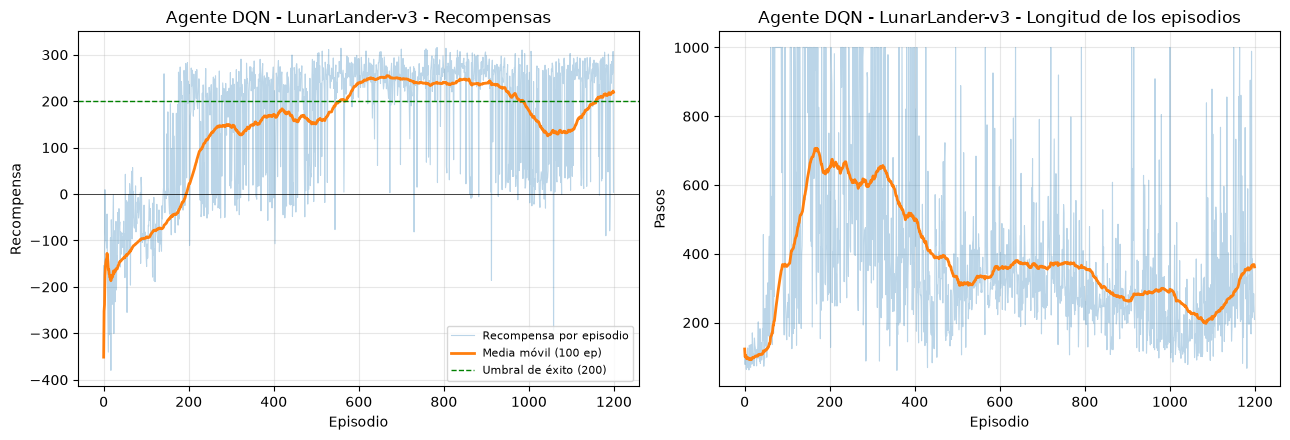

Resultados de los últimos 100 episodios de entrenamiento:
Recompensa promedio: 219.31
Tasa de éxito (R ≥ 200): 80.0%
Epsilon final: 0.050


In [15]:
# Graficar progreso del entrenamiento
graficar_progreso_entrenamiento(recompensas_episodios, longitudes_episodios,
                                "Agente DQN - LunarLander-v3")

# Resultados del final del entrenamiento (todavía con exploración residual)
ultimos = np.array(recompensas_episodios[-100:])
print("Resultados de los últimos 100 episodios de entrenamiento:")
print(f"Recompensa promedio: {ultimos.mean():.2f}")
print(f"Tasa de éxito (R ≥ 200): {(ultimos >= UMBRAL_EXITO).mean():.1%}")
print(f"Epsilon final: {getattr(agente_dqn, 'epsilon', float('nan')):.3f}")

In [16]:
# Opcional: guardar los pesos de la red para no reentrenar en otra sesión, p. ej.
# torch.save(agente_dqn.red_q.state_dict(), 'dqn_lunarlander.pt')
# y recargarlos con agente_dqn.red_q.load_state_dict(torch.load('dqn_lunarlander.pt')).


## 8. Evaluación del agente entrenado

Se evalúan 200 episodios, sin exploración, sobre semillas fijas
(`10000 … 10199`). El agente aleatorio se vuelve a evaluar en la misma celda con
esas mismas semillas, de modo que ambos agentes enfrenten los mismos escenarios
iniciales.

In [17]:
# Evaluar el agente DQN entrenado
env = gym.make('LunarLander-v3')

print("Evaluando agente DQN entrenado (200 episodios, sin exploración)...")
resultados_dqn = evaluar_agente(agente_dqn, env, num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_dqn, "Agente DQN entrenado")

print("\nImplementación de referencia para comparar:")
resultados_aleatorio_200 = evaluar_agente(AgenteAleatorio(env.action_space, semilla=SEMILLA), env,
                                          num_episodios=200, semilla=10_000)
imprimir_resultados_evaluacion(resultados_aleatorio_200, "Agente aleatorio")

env.close()

Evaluando agente DQN entrenado (200 episodios, sin exploración)...



Agente DQN entrenado - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 77.5%
Recompensa promedio: 235.79
Recompensa mediana:  262.43
Desviación estándar: 67.42
Total de éxitos: 155 / 200

Implementación de referencia para comparar:



Agente aleatorio - Resultados de evaluación:
Tasa de éxito (R ≥ 200): 0.0%
Recompensa promedio: -183.17
Recompensa mediana:  -149.80
Desviación estándar: 111.96
Total de éxitos: 0 / 200


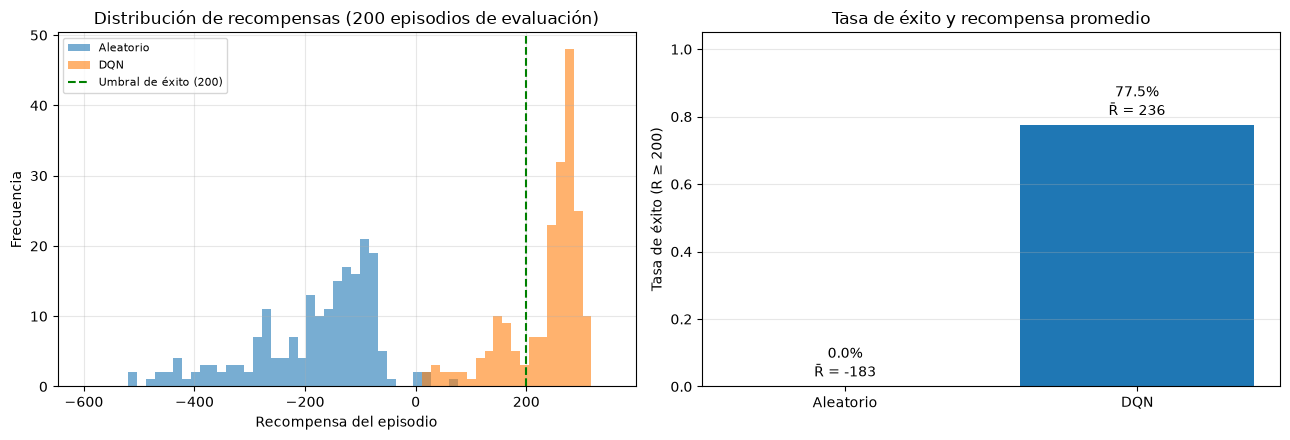

Tasa de éxito DQN:       77.5%
Tasa de éxito Aleatorio: 0.0%
Mejora en recompensa promedio: 419.0 puntos

Desglose de los 200 episodios del DQN:
  R ≥  200:  77.5%
  R ≥  150:  87.5%
  R ≥  100:  94.0%
  R ≥    0: 100.0%
  Episodios que se estrellan (R < -50): 0.0%


In [18]:
# Comparación gráfica: DQN vs. agente aleatorio
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

bins = np.linspace(-600, 350, 60)
ax1.hist(resultados_aleatorio_200['recompensas_totales'], bins=bins, alpha=0.6, label="Aleatorio")
ax1.hist(resultados_dqn['recompensas_totales'], bins=bins, alpha=0.6, label="DQN")
ax1.axvline(UMBRAL_EXITO, color='green', linestyle='--', label="Umbral de éxito (200)")
ax1.set_title("Distribución de recompensas (200 episodios de evaluación)")
ax1.set_xlabel("Recompensa del episodio")
ax1.set_ylabel("Frecuencia")
ax1.legend(fontsize=8)
ax1.grid(True, alpha=0.3)

nombres = ["Aleatorio", "DQN"]
tasas = [resultados_aleatorio_200['tasa_exito'], resultados_dqn['tasa_exito']]
promedios = [resultados_aleatorio_200['recompensa_promedio'], resultados_dqn['recompensa_promedio']]

barras = ax2.bar(nombres, tasas, color=['tab:gray', 'tab:blue'])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Tasa de éxito (R ≥ 200)")
ax2.set_title("Tasa de éxito y recompensa promedio")
for barra, tasa, promedio in zip(barras, tasas, promedios):
    ax2.text(barra.get_x() + barra.get_width() / 2, tasa + 0.03,
             f"{tasa:.1%}\nR̄ = {promedio:.0f}", ha='center', fontsize=10)
ax2.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Tasa de éxito DQN:       {resultados_dqn['tasa_exito']:.1%}")
print(f"Tasa de éxito Aleatorio: {resultados_aleatorio_200['tasa_exito']:.1%}")
print(f"Mejora en recompensa promedio: "
      f"{resultados_dqn['recompensa_promedio'] - resultados_aleatorio_200['recompensa_promedio']:.1f} puntos")

# El umbral de 200 es un corte tajante: desglose de la cola de la distribución.
r_dqn = resultados_dqn['recompensas_totales']
print("\nDesglose de los 200 episodios del DQN:")
for corte in (200, 150, 100, 0):
    print(f"  R ≥ {corte:4d}: {(r_dqn >= corte).mean():6.1%}")
print(f"  Episodios que se estrellan (R < -50): {(r_dqn < -50).mean():.1%}")

Además, el agente principal se evaluó en los **200 escenarios de test** (30000 a 30199), que
no se usaron para ninguna decisión. Son los mismos escenarios del estudio de ablación.

In [19]:
env = gym.make('LunarLander-v3')
retornos_test, finales_test = evaluar_con_finales(agente_dqn, env, EPISODIOS_TEST, SEMILLA_TEST)
env.close()

retornos_test = np.array(retornos_test)
exitos_test = int((retornos_test >= UMBRAL_EXITO).sum())
print(f"Escenarios de test 30000-30199: retorno medio {retornos_test.mean():.2f} "
      f"(DE {retornos_test.std():.2f}), {exitos_test}/200 éxitos ({exitos_test / 200:.1%})")
for fin in ['posado', 'choque', 'truncado']:
    print(f"  {fin:>9}: {finales_test.count(fin)}")

# DQN no mejora de forma monótona: máximo y mínimo de la media móvil
media_100 = media_movil(recompensas_episodios, 100)
episodio_maximo = int(media_100.argmax()) + 1
episodio_minimo = episodio_maximo + int(media_100[episodio_maximo:].argmin()) + 1
print(f"\nMedia móvil de 100 episodios: {media_100[99]:.1f} en el episodio 100, "
      f"{media_100[299]:.1f} en el 300, máximo {media_100.max():.1f} en el {episodio_maximo}, "
      f"después baja a {media_100[episodio_minimo - 1]:.1f} en el {episodio_minimo} "
      f"y termina en {media_100[-1]:.1f}")

Escenarios de test 30000-30199: retorno medio 240.21 (DE 65.13), 162/200 éxitos (81.0%)
     posado: 165
     choque: 3
   truncado: 32

Media móvil de 100 episodios: -95.2 en el episodio 100, 145.0 en el 300, máximo 254.9 en el 668, después baja a 125.3 en el 1045 y termina en 219.3


## 9. Visualización de la política aprendida

Se corren 10 episodios sin exploración sobre semillas sorteadas, sin elegir
los que salieron bien, y se arma un GIF con los diez en una grilla. Cada cuadro
muestra al terminar la recompensa del episodio, en verde si llegó al umbral de éxito
y en rojo si no.

  semilla 20892:  160 pasos, recompensa   295.8


  semilla 27739:  208 pasos, recompensa   273.1


  semilla 26545:  865 pasos, recompensa   214.3


  semilla 24388:  431 pasos, recompensa   273.1


  semilla 24330:  166 pasos, recompensa   314.0


  semilla 28585:  369 pasos, recompensa   250.0


  semilla 20859:  175 pasos, recompensa   249.2


  semilla 26973:  516 pasos, recompensa   289.1


  semilla 22014: 1000 pasos, recompensa    96.0


  semilla 20941:  153 pasos, recompensa   264.2



9/10 episodios exitosos, recompensa media 251.9 → aterrizaje_dqn.gif


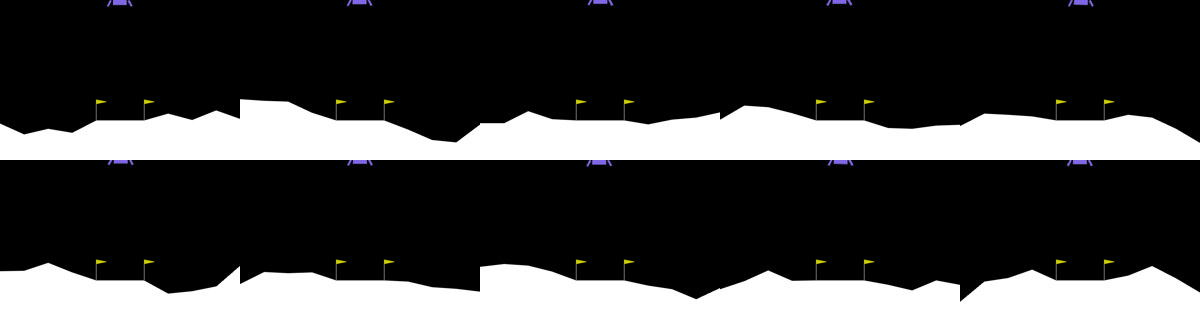

In [20]:
from PIL import Image, ImageDraw
from IPython.display import Image as MostrarImagen, display

ANCHO_CUADRO, ALTO_CUADRO = 240, 160

def _correr_episodio_render(agente, env, semilla, salto):
    """Corre un episodio renderizando y devuelve (cuadros, recompensa, pasos)."""
    estado, _ = env.reset(seed=semilla)
    cuadros, recompensa_total, paso = [], 0.0, 0
    while True:
        if paso % salto == 0:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
        estado, recompensa, terminado, truncado, _ = env.step(agente.elegir_accion(estado, explorar=False))
        recompensa_total += recompensa
        paso += 1
        if terminado or truncado:
            cuadros.append(Image.fromarray(env.render()).resize((ANCHO_CUADRO, ALTO_CUADRO)))
            break
    return cuadros, recompensa_total, paso


def _rotular(cuadro, recompensa, umbral):
    """Escribe la recompensa final sobre el cuadro: verde si es éxito, rojo si no."""
    cuadro = cuadro.copy()
    color = (40, 170, 70) if recompensa >= umbral else (210, 50, 50)
    ImageDraw.Draw(cuadro).text((6, 4), f"R = {recompensa:.0f}", fill=color)
    return cuadro


def grabar_episodios(agente, ruta_gif='aterrizaje_dqn.gif', semillas=range(10_000, 10_010),
                     columnas=5, salto=3, umbral=UMBRAL_EXITO):
    """Corre un episodio sin exploración por semilla y guarda un GIF con todos en
    una grilla. Los episodios que terminan antes quedan quietos en su último cuadro,
    rotulado con la recompensa obtenida."""
    env = gym.make('LunarLander-v3', render_mode='rgb_array')
    episodios = []
    try:
        for semilla in semillas:
            cuadros, recompensa_total, pasos = _correr_episodio_render(agente, env, semilla, salto)
            print(f"  semilla {semilla}: {pasos:4d} pasos, recompensa {recompensa_total:7.1f}")
            cuadros[-1] = _rotular(cuadros[-1], recompensa_total, umbral)
            episodios.append((cuadros, recompensa_total))
    finally:
        env.close()

    filas = -(-len(episodios) // columnas)
    largo = max(len(cuadros) for cuadros, _ in episodios)
    fotogramas = []
    for t in range(largo):
        lienzo = Image.new('RGB', (columnas * ANCHO_CUADRO, filas * ALTO_CUADRO), 'white')
        for i, (cuadros, _) in enumerate(episodios):
            lienzo.paste(cuadros[min(t, len(cuadros) - 1)],
                         ((i % columnas) * ANCHO_CUADRO, (i // columnas) * ALTO_CUADRO))
        fotogramas.append(lienzo)
    fotogramas[0].save(ruta_gif, save_all=True, append_images=fotogramas[1:], duration=50, loop=0)

    recompensas = np.array([r for _, r in episodios])
    print(f"\n{(recompensas >= umbral).sum()}/{len(recompensas)} episodios exitosos, "
          f"recompensa media {recompensas.mean():.1f} → {ruta_gif}")
    return ruta_gif, recompensas


# Semillas sorteadas, no elegidas: el GIF muestra los diez episodios salgan como salgan.
semillas_gif = np.random.default_rng(SEMILLA).integers(20_000, 30_000, size=10).tolist()
ruta, _ = grabar_episodios(agente_dqn, semillas=semillas_gif)
display(MostrarImagen(filename=ruta))

## 10. Qué aprendió la política

Analicen la política aprendida utilizando cortes con valores fijos en algunas
dimensiones para validar lo aprendido.


### TODO 2: cortes de la política

Se analiza el **agente principal**. Se parte de un estado de referencia, la nave sobre la
plataforma a media altura, bajando despacio y derecha
($x=v_x=\theta=\omega=c_1=c_2=0$, $y=0{,}8$, $v_y=-0{,}3$), y se varían solo dos variables en
una grilla de $101\times101$: $(x, v_x)$, $(\theta, \omega)$ y $(y, v_y)$. Las otras seis quedan
fijas. Cada punto muestra la acción que elige la red.

Los ejes son las **observaciones que entrega Gymnasium**, ya escaladas: no son metros ni m/s.
$\theta$ está en radianes.

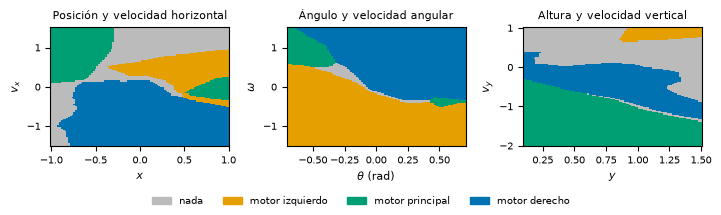

In [21]:
NOMBRES_ACCIONES = ['nada', 'motor izquierdo', 'motor principal', 'motor derecho']
COLORES = ListedColormap(['#bbbbbb', '#e69f00', '#009e73', '#0072b2'])
NORMA = BoundaryNorm(np.arange(-0.5, 4.5, 1), 4)
ESTADO_REFERENCIA = np.array([0, 0.8, 0, -0.3, 0, 0, 0, 0], dtype=np.float32)
CORTES = [  # (índice x, índice y, rango x, rango y, etiqueta x, etiqueta y, título)
    (0, 2, (-1, 1), (-1.5, 1.5), '$x$', '$v_x$', 'Posición y velocidad horizontal'),
    (4, 5, (-0.7, 0.7), (-1.5, 1.5), r'$\theta$ (rad)', r'$\omega$', 'Ángulo y velocidad angular'),
    (1, 3, (0.1, 1.5), (-2, 1), '$y$', '$v_y$', 'Altura y velocidad vertical'),
]


def acciones_del_corte(red_q, ix, iy, rango_x, rango_y):
    """Acción greedy en una grilla de 101x101 que varía dos valores del estado de referencia."""
    xs = np.linspace(rango_x[0], rango_x[1], 101)
    ys = np.linspace(rango_y[0], rango_y[1], 101)
    malla_x, malla_y = np.meshgrid(xs, ys)
    estados = np.tile(ESTADO_REFERENCIA, (malla_x.size, 1))
    estados[:, ix] = malla_x.ravel()
    estados[:, iy] = malla_y.ravel()
    with torch.no_grad():
        valores_q = red_q(torch.from_numpy(estados))
    acciones = valores_q.argmax(dim=1).numpy().reshape(101, 101)
    return xs, ys, acciones


def agregar_leyenda(fig):
    parches = []
    for i, nombre in enumerate(NOMBRES_ACCIONES):
        parches.append(Patch(color=COLORES(i), label=nombre))
    fig.legend(handles=parches, loc='lower center', ncol=4, frameon=False, fontsize=7)


fig, ejes = plt.subplots(1, 3, figsize=(7.16, 2.05))
fig.subplots_adjust(left=0.07, right=0.98, bottom=0.31, top=0.89, wspace=0.32)
for eje, (ix, iy, rx, ry, lx, ly, titulo) in zip(ejes, CORTES):
    xs, ys, acciones = acciones_del_corte(agente_dqn.red_q, ix, iy, rx, ry)
    eje.pcolormesh(xs, ys, acciones, cmap=COLORES, norm=NORMA, shading='auto', rasterized=True)
    eje.set_title(titulo, fontsize=8)
    eje.set_xlabel(lx, fontsize=8)
    eje.set_ylabel(ly, fontsize=8)
    eje.tick_params(labelsize=7)
agregar_leyenda(fig)
fig.savefig(CARPETA_FIGURAS / 'cortes_politica.pdf')
plt.show()

## 11. Estudio de ablación

Las secciones anteriores muestran que el DQN completo funciona, pero no *cuánto*
aporta cada una de sus piezas. Una **ablación** responde eso: se reentrena el
agente desde cero desactivando (o degradando) un componente por vez y se mide
cuánto cae el desempeño respecto de la configuración completa.

Comparen el DQN completo contra, como mínimo, tres variantes correspondientes a
quitar características de DQN. Cada configuración se entrena con varias semillas y
se evalúa sobre las mismas semillas de evaluación, sin exploración. Reporten para
cada variante la recompensa de evaluación por semilla y comparen contra el DQN
completo con un test estadístico adecuado.


### TODO 3: estudio de ablación

**Variantes.** Cada una quita un solo componente y deja todo lo demás igual:

* **Sin red objetivo**: el valor futuro se calcula con la misma red que se entrena.
* **Sin replay**: cada actualización usa solo la transición que acaba de pasar (minilote de 1),
  con la misma frecuencia de actualización.
* **Sin exploración**: $\varepsilon = 0$ desde el principio.

**Diseño.** Las cuatro condiciones (completo y tres variantes) se entrenan 300 episodios con las
**mismas ocho semillas**, en la misma computadora, y se evalúan sin explorar en los **mismos 200
escenarios de test** (30000 a 30199). Cada agente entrenado es un dato: el promedio de sus 200
episodios.

**Test.** Cada variante se compara con el completo con el test U de **Mann–Whitney** bilateral
exacto sobre las ocho medias de cada condición, con corrección de **Holm** para las tres
comparaciones ($\alpha = 0{,}05$).

Las semillas 42, 1042 y 2042 también se usaron en la calibración: con esas semillas, las corridas
del completo son las mismas que eligió la calibración.

In [22]:
VARIANTES = {  # componente que se quita en cada condición
    'completo': {},
    'sin_objetivo': dict(usar_red_objetivo=False),
    'sin_replay': dict(usar_replay=False),
    'sin_exploracion': dict(usar_exploracion=False),
}
NOMBRES = {'completo': 'Completo', 'sin_objetivo': 'Sin red objetivo',
           'sin_replay': 'Sin replay', 'sin_exploracion': 'Sin exploración'}

trabajos = []
for variante, quitar in VARIANTES.items():
    cambios = dict(CONFIGURACION_FINAL)
    cambios.update(quitar)
    guardar_pesos = (variante == 'completo')
    for semilla in SEMILLAS_ESTUDIO:
        nombre = f'estudio_{variante}_s{semilla}'
        trabajos.append((nombre, cambios, semilla, EPISODIOS_ESTUDIO,
                         SEMILLA_TEST, EPISODIOS_TEST, guardar_pesos))
estudio = obtener_corridas(trabajos)

# Cada agente entrenado es un dato: el promedio de sus 200 episodios de test
medias = {}
for variante in VARIANTES:
    valores = []
    for semilla in SEMILLAS_ESTUDIO:
        corrida = estudio[f'estudio_{variante}_s{semilla}']
        valores.append(np.mean(corrida['retornos']))
    medias[variante] = np.array(valores)

print('Recompensa media de evaluación (200 escenarios de test) por semilla de entrenamiento:\n')
print('Semilla     Completo   Sin objetivo   Sin replay   Sin exploración')
for i, semilla in enumerate(SEMILLAS_ESTUDIO):
    print(f"{semilla:7d}{medias['completo'][i]:13.1f}{medias['sin_objetivo'][i]:15.1f}"
          f"{medias['sin_replay'][i]:13.1f}{medias['sin_exploracion'][i]:18.1f}")
print()

for variante in VARIANTES:
    exitos = 0
    semillas_sobre_10 = 0
    finales = []
    for semilla in SEMILLAS_ESTUDIO:
        corrida = estudio[f'estudio_{variante}_s{semilla}']
        exitos_corrida = int((np.array(corrida['retornos']) >= UMBRAL_EXITO).sum())
        exitos += exitos_corrida
        if exitos_corrida / EPISODIOS_TEST > 0.10:
            semillas_sobre_10 += 1
        finales.extend(corrida['finales'])
    print(f"{NOMBRES[variante]:<17} media {medias[variante].mean():6.1f} | "
          f"DE entre semillas {medias[variante].std(ddof=1):5.1f} | "
          f"éxitos {exitos}/1600 ({exitos / 1600:.1%}) | semillas con >10%: {semillas_sobre_10}/8 | "
          f"posado {finales.count('posado')}, choque {finales.count('choque')}, "
          f"truncado {finales.count('truncado')}")

Recompensa media de evaluación (200 escenarios de test) por semilla de entrenamiento:

Semilla     Completo   Sin objetivo   Sin replay   Sin exploración
     42         -2.1         -166.9       -148.0            -165.5
   1042        231.5          150.8        -76.8              63.4
   2042        250.5          205.8         17.3             156.3
   3042         72.3           73.8        -39.7             -72.1
   4042        -23.8          178.1        118.3            -133.8
   5042         38.2          219.8         15.0              69.4
   6042        220.8         -166.5         -3.3             127.1
   7042        194.5         -524.6        176.3             170.9

Completo          media  122.7 | DE entre semillas 113.2 | éxitos 710/1600 (44.4%) | semillas con >10%: 5/8 | posado 822, choque 55, truncado 723
Sin red objetivo  media   -3.7 | DE entre semillas 262.2 | éxitos 563/1600 (35.2%) | semillas con >10%: 5/8 | posado 727, choque 657, truncado 216
Sin replay      

Complemento de la sección 10: el mismo corte del ángulo para los ocho agentes completos del
estudio, para ver si lo aprendido depende de la semilla:

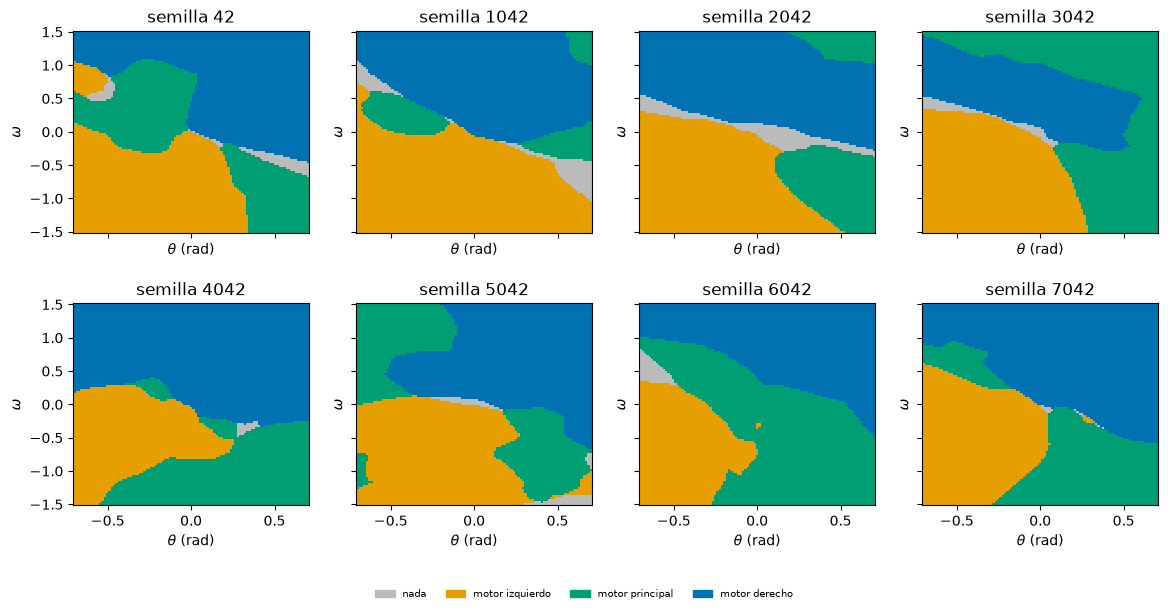

In [23]:
fig, ejes = plt.subplots(2, 4, figsize=(14, 6.5), sharex=True, sharey=True)
ix, iy, rx, ry, lx, ly, _ = CORTES[1]
for eje, semilla in zip(ejes.ravel(), SEMILLAS_ESTUDIO):
    pesos = estudio[f'estudio_completo_s{semilla}']['pesos']
    agente = agente_desde_pesos(pesos)
    xs, ys, acciones = acciones_del_corte(agente.red_q, ix, iy, rx, ry)
    eje.pcolormesh(xs, ys, acciones, cmap=COLORES, norm=NORMA, shading='auto')
    eje.set_title(f'semilla {semilla}')
    eje.set_xlabel(lx)
    eje.set_ylabel(ly)
agregar_leyenda(fig)
fig.subplots_adjust(bottom=0.15, hspace=0.35)
plt.show()

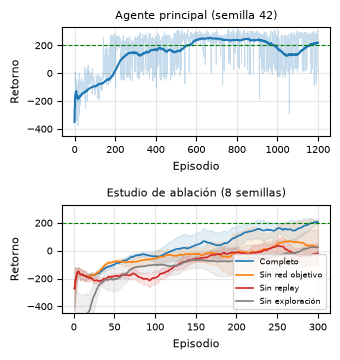

In [24]:
# Curvas de aprendizaje: agente principal (1200 episodios) y estudio (300 episodios, 8 semillas)
fig, (eje1, eje2) = plt.subplots(2, 1, figsize=(3.5, 3.7))
eje1.plot(recompensas_episodios, color='tab:blue', alpha=0.25, linewidth=0.6)
eje1.plot(media_movil(recompensas_episodios, 100), color='tab:blue', linewidth=1.5)
eje1.set_title('Agente principal (semilla 42)')

colores_variantes = {'completo': 'tab:blue', 'sin_objetivo': 'tab:orange',
                     'sin_replay': 'tab:red', 'sin_exploracion': 'tab:gray'}
for variante in VARIANTES:
    curvas = []
    for semilla in SEMILLAS_ESTUDIO:
        recompensas = estudio[f'estudio_{variante}_s{semilla}']['recompensas']
        curvas.append(media_movil(recompensas, 20))
    curvas = np.array(curvas)
    promedio = curvas.mean(axis=0)
    desvio = curvas.std(axis=0, ddof=1)
    episodios = np.arange(1, len(promedio) + 1)
    color = colores_variantes[variante]
    eje2.plot(episodios, promedio, color=color, label=NOMBRES[variante], linewidth=1.2)
    eje2.fill_between(episodios, promedio - desvio, promedio + desvio, color=color, alpha=0.12)
eje2.set_title('Estudio de ablación (8 semillas)')
eje2.legend(fontsize=6, loc='lower right')

for eje in (eje1, eje2):
    eje.axhline(UMBRAL_EXITO, color='green', linestyle='--', linewidth=0.8)
    eje.set_ylim(-450, 330)   # sin exploración empieza cerca de -1000; se recorta para que se lea el resto
    eje.set_xlabel('Episodio', fontsize=8)
    eje.set_ylabel('Retorno', fontsize=8)
    eje.title.set_size(8)
    eje.tick_params(labelsize=7)
    eje.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(CARPETA_FIGURAS / 'curvas_aprendizaje.pdf')
plt.show()

In [25]:
def holm(p_valores):
    """Corrección de Holm: ordena los p de menor a mayor y los multiplica por m, m-1, ..., 1."""
    m = len(p_valores)
    orden = np.argsort(p_valores)
    ajustados = np.zeros(m)
    maximo = 0.0
    for posicion, i in enumerate(orden):
        ajustado = min(1.0, (m - posicion) * p_valores[i])
        maximo = max(maximo, ajustado)   # los ajustados no pueden bajar
        ajustados[i] = maximo
    return ajustados


ABLACIONES = ['sin_objetivo', 'sin_replay', 'sin_exploracion']
diferencias = []
estadisticos_u = []
p_valores = []
for variante in ABLACIONES:
    resultado = stats.mannwhitneyu(medias['completo'], medias[variante],
                                   alternative='two-sided', method='exact')
    diferencias.append(medias['completo'].mean() - medias[variante].mean())
    estadisticos_u.append(resultado.statistic)
    p_valores.append(resultado.pvalue)
p_holm = holm(p_valores)

print('Variante            Δ media     U    p MW   p Holm')
for i, variante in enumerate(ABLACIONES):
    print(f'{NOMBRES[variante]:<17}{diferencias[i]:9.1f}{estadisticos_u[i]:6.0f}'
          f'{p_valores[i]:8.4f}{p_holm[i]:9.4f}')
print('\nΔ: retorno medio del completo menos el de la variante. U corresponde al completo.')
significativas = []
for i, variante in enumerate(ABLACIONES):
    if p_holm[i] < 0.05:
        significativas.append(NOMBRES[variante])
print('Significativas con Holm (α = 0,05):', significativas)

Variante            Δ media     U    p MW   p Holm
Sin red objetivo     126.4    42  0.3282   0.3282
Sin replay           115.3    51  0.0499   0.1497
Sin exploración       95.8    46  0.1605   0.3211

Δ: retorno medio del completo menos el de la variante. U corresponde al completo.
Significativas con Holm (α = 0,05): []
